# Tiamat 
=======================================

**Disciplina:** Aprendizado de máquina 

**Professor**: Daniel Roberto Cassar 

**Aluna:** Bruna Henrique Fujihashi

**Monstro:** Tiamat

# Introdução 

aqui vamos escrever o desenvolvimento

# Desenvolvimento 

## Bibliotecas

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from math import ceil 
import optuna
from functools import partial
from scipy.spatial.distance import cdist
from scipy.stats import mannwhitneyu
from sklearn.decomposition import PCA
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.inspection import PartialDependenceDisplay, permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    RocCurveDisplay,
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import GroupShuffleSplit, StratifiedGroupKFold, cross_val_score
from sklearn.neighbors import KNeighborsClassifier, NearestNeighbors
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.svm import SVC

## Pré-definições 

In [3]:
SEMENTE_ALEATORIA = 69
LIMIAR_CORRELACAO = 0.9

TAMANHO_TESTE = 0.2
NIVEL_CONFIANCA = 0.95
NUM_BINS = 30
NUM_FOLDS = 5
NUM_TENTATIVAS = 100            # tentativas do Optuna por algoritmo
METRICA = "balanced_accuracy"   # métrica otimizada pelo Optuna e usada na comparação
ARQUIVO_ESTUDOS = "estudos_optuna.db"

# Arredondamento usado SÓ para identificar exemplos quase redundantes (ver seção de exemplos redundantes)
CASAS_ARREDONDAMENTO_PADRAO = 2
CASAS_ARREDONDAMENTO_POR_ATRIBUTO = {}   # exceções por atributo, ex.: {"nome_do_atributo": 0}

In [4]:
optuna.logging.set_verbosity(optuna.logging.WARNING)

## Descrição dos dados

descrever de onde os dados vieram e citar a autoria 

### Coleta dos dados 

In [5]:
# Coleta dos dados do dataset escolhido 
df_biodeg_leitura = pd.read_csv("biodeg.csv")

df_biodeg_leitura

,3.919;2.6909;0;0;0;0;0;31.4;2;0;0;0;3.106;2.55;9.002;0;0.96;1.142;0;0;0;1.201;0;0;0;0;1.932;0.011;0;0;4.489;0;0;0;0;2.949;1.591;0;7.253;0;0;RB
0,4.17;2.1144;0;0;0;0;0;30.8;1;1;0;0;2.461;1.393...
1,3.932;3.2512;0;0;0;0;0;26.7;2;4;0;0;3.279;2.58...
2,3;2.7098;0;0;0;0;0;20;0;2;0;0;2.1;0.918;6.594;...
3,4.236;3.3944;0;0;0;0;0;29.4;2;4;0;-0.271;3.449...
4,4.236;3.4286;0;0;0;0;0;28.6;2;4;0;-0.275;3.313...
...,...
1049,5.431;2.8955;0;0;0;2;0;32.1;4;1;1;0.374;3.233;...
1050,5.287;3.3732;0;0;9;0;0;35.3;0;9;9;-5.256;4.319...
1051,4.869;1.767;0;1;9;0;5;44.4;0;4;14;-0.391;4.435...
1052,5.158;1.6914;2;0;36;0;9;56.1;0;0;44;0;4.902;0....


### Tratamento do dataset

In [9]:
# Criar os nomes das colunas
colunas = [f"atributo_{i}" for i in range(1, 42)]
colunas.append("classe")

# Coleta dos dados (separador, sem cabeçalho, nomes das colunas)
df_biodeg = pd.read_csv("biodeg.csv", sep=";", header=None, names=colunas)

# Cópia do dataframe
df_biodeg_copy = df_biodeg.copy()

# Conferir formato do dataset
print(f'formato do dataset: \n{df_biodeg_copy.shape}')
print()

# Limpeza básica
df_biodeg_copy["classe"] = df_biodeg_copy["classe"].str.strip()

# Remove as linhas idênticas em todas as colunas, ou seja, atributos de classe.
df_biodeg_copy = df_biodeg_copy.dropna(how="all").drop_duplicates()

# Garantir que as features são numéricas
features = df_biodeg_copy.columns.drop("classe")
df_biodeg_copy[features] = df_biodeg_copy[features].apply(pd.to_numeric, errors="coerce")

# Checagens
print(f'Tipos de objetos\n{df_biodeg_copy.dtypes.value_counts()}') # contagem dos tipos de objetos que temos 
print()
print(f'valores nulos: {df_biodeg_copy.isna().sum().sum()}') # contagem do número de valores nulos (NAN)
print()
print(df_biodeg_copy["classe"].value_counts()) # checagem da proporção dos targets

# Transformação do target em binário (0/1) para utilizar no modelo
df_biodeg_copy["classe_bin"] = (df_biodeg_copy["classe"] == "RB").astype(int)

formato do dataset: 
(1055, 42)

Tipos de objetos
int64      24
float64    17
object      1
Name: count, dtype: int64

valores nulos: 0

classe
NRB    698
RB     354
Name: count, dtype: int64


In [10]:
df_biodeg_copy.T

,0,1,2,3,4,5,6,7,8,9,...,1045,1046,1047,1048,1049,1050,1051,1052,1053,1054
atributo_1,3.919,4.17,3.932,3.0,4.236,4.236,5.0,4.525,4.596,5.04,...,4.607,5.313,5.103,5.265,5.029,5.431,5.287,4.869,5.158,5.076
atributo_2,2.6909,2.1144,3.2512,2.7098,3.3944,3.4286,5.0476,3.8301,3.0777,3.6112,...,3.0008,2.7782,3.9184,3.3444,2.5966,2.8955,3.3732,1.767,1.6914,2.6588
atributo_3,0,0,0,0,0,0,1,0,0,0,...,1,0,0,2,0,0,0,0,2,2
atributo_4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,1,0,0
atributo_5,0,0,0,0,0,0,0,0,0,1,...,0,0,4,6,0,0,9,9,36,0
atributo_6,0,0,0,0,0,0,0,0,0,0,...,0,1,0,0,0,2,0,0,0,0
atributo_7,0,0,0,0,0,0,0,0,2,2,...,2,2,4,1,4,0,0,5,9,4
atributo_8,31.4,30.8,26.7,20.0,29.4,28.6,11.1,31.6,44.4,41.2,...,41.2,40.0,35.0,35.3,46.7,32.1,35.3,44.4,56.1,54.5
atributo_9,2,1,2,0,2,2,0,3,2,0,...,0,4,1,2,0,4,0,0,0,0
atributo_10,0,1,4,2,4,4,3,2,0,4,...,1,1,5,3,4,1,9,4,0,0


### Separação dos features e do target 

Após a coleta e limpeza dos dados, vamos separar quais são os fetures e qual é o target. É possível perceber que os features já foram transformados em binários, mantendo o formado em string também. Por isso, para definir o X, vamos somente excluir as colunas em que esses dois formatos se encontram. Em Y, vamos resgatar somente a coluna "classe", pois ela já está convertida na forma binária, que vai útil para o nosso objetivo. Salvamos os dois tipos de classes, binária e string, para poder utilizar os rótulos futuramente. 

In [11]:
# Atributos (X) e target (y). Atenção: "classe_bin" é o target em formato numérico, então precisa ficar FORA de X, senão o modelo veria a resposta (vazamento do target).
X = df_biodeg_copy.drop(columns=["classe", "classe_bin"])
y_str = df_biodeg_copy["classe"]               # rótulos originais: RB ou NRB
y_binario = df_biodeg_copy["classe_bin"]   # 1 = RB, 0 = NRB
print(f"Daddos dos features (X)")
print(f"Número de exemplos: {X.shape[0]}")
print(f"Número de atributos: {X.shape[1]}")

Daddos dos features (X)
Número de exemplos: 1052
Número de atributos: 41


## Análise exploratória dos dados 

### Estrutura Geral e valores ausentes 

Citar o .isna() e o .sum() como sugestão da IA. Por ser um dataset grande, foi preferível encontrar uma alternativa que poderia fazer essa verificação de valores ausentes sem que fosse necessário olhar cada coluna individualmente. Visto que o dataset tem muitos valores zero, que não são nulos, optei por utilizar o .isna(). O primeiro .sum() soma quantos valores NAN existem em cada coluna e o segundo, quantos valores nulos existem no total. 

In [13]:
# Conta quantas colunas existem de cada tipo: int64 ou float64
print(X.dtypes.value_counts())

# O .isna() dá uma tabela de True/False para cada célula ausente. 
print(f"\nTotal de valores ausentes nos atributos: {X.isna().sum().sum()}")
print(f"Valores ausentes no target: {y_binario.isna().sum()}")

X.describe().T # o dataframe foi transposto para a melhor vizualização dos dados, esse passo é opcional.

int64      24
float64    17
Name: count, dtype: int64

Total de valores ausentes nos atributos: 0
Valores ausentes no target: 0


,count,mean,std,min,25%,50%,75%,max
atributo_1,1052.0,4.781716,0.546207,2.0000,4.481000,4.8280,5.125000,6.4960
atributo_2,1052.0,3.068678,0.830434,0.8039,2.506425,3.0460,3.432575,9.1775
atributo_3,1052.0,0.712928,1.455102,0.0000,0.000000,0.0000,1.000000,12.0000
atributo_4,1052.0,0.042776,0.256365,0.0000,0.000000,0.0000,0.000000,3.0000
atributo_5,1052.0,0.982890,2.335693,0.0000,0.000000,0.0000,1.000000,36.0000
atributo_6,1052.0,0.288023,1.071972,0.0000,0.000000,0.0000,0.000000,13.0000
atributo_7,1052.0,1.651141,2.226253,0.0000,0.000000,1.0000,3.000000,18.0000
atributo_8,1052.0,37.065494,9.143839,0.0000,30.475000,37.5000,43.350000,60.7000
atributo_9,1052.0,1.378327,1.965309,0.0000,0.000000,1.0000,2.000000,24.0000
atributo_10,1052.0,1.798479,1.771773,0.0000,0.000000,2.0000,3.000000,12.0000


### Distribuição das classes 

foi feita uma função para analisar a distribuição das classes do target. 

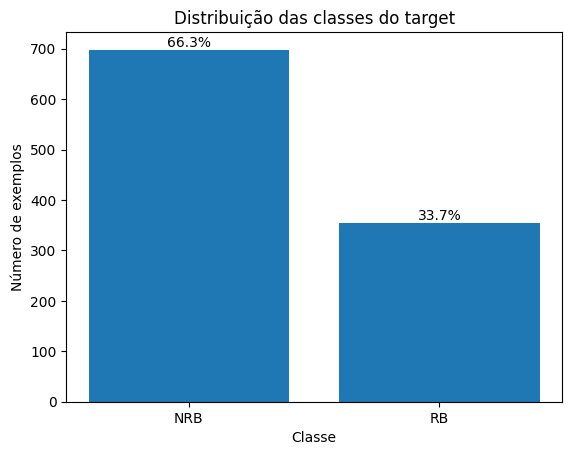

In [15]:
def plota_distribuicao_classes(y):

    # O .value_counts() conta exemplos por classe.
    contagem = y_str.value_counts()
    # Aqui, dividimos a contagem pelo total e multiplicamos por 100, assim, encontrando a porcentagem.
    proporcao = contagem / contagem.sum() * 100

    # Plot do gráfico de barras
    barras = plt.bar(contagem.index, contagem.values)   
    plt.bar_label(barras, labels=[f"{p:.1f}%" for p in proporcao])      
    plt.title("Distribuição das classes do target")
    plt.xlabel("Classe")
    plt.ylabel("Número de exemplos")
    plt.show()

    return proporcao


proporcao_classes = plota_distribuicao_classes(y_binario)

### Distribuição dos atributos 

explicar as normalizações e bibliotecas utilizadas 

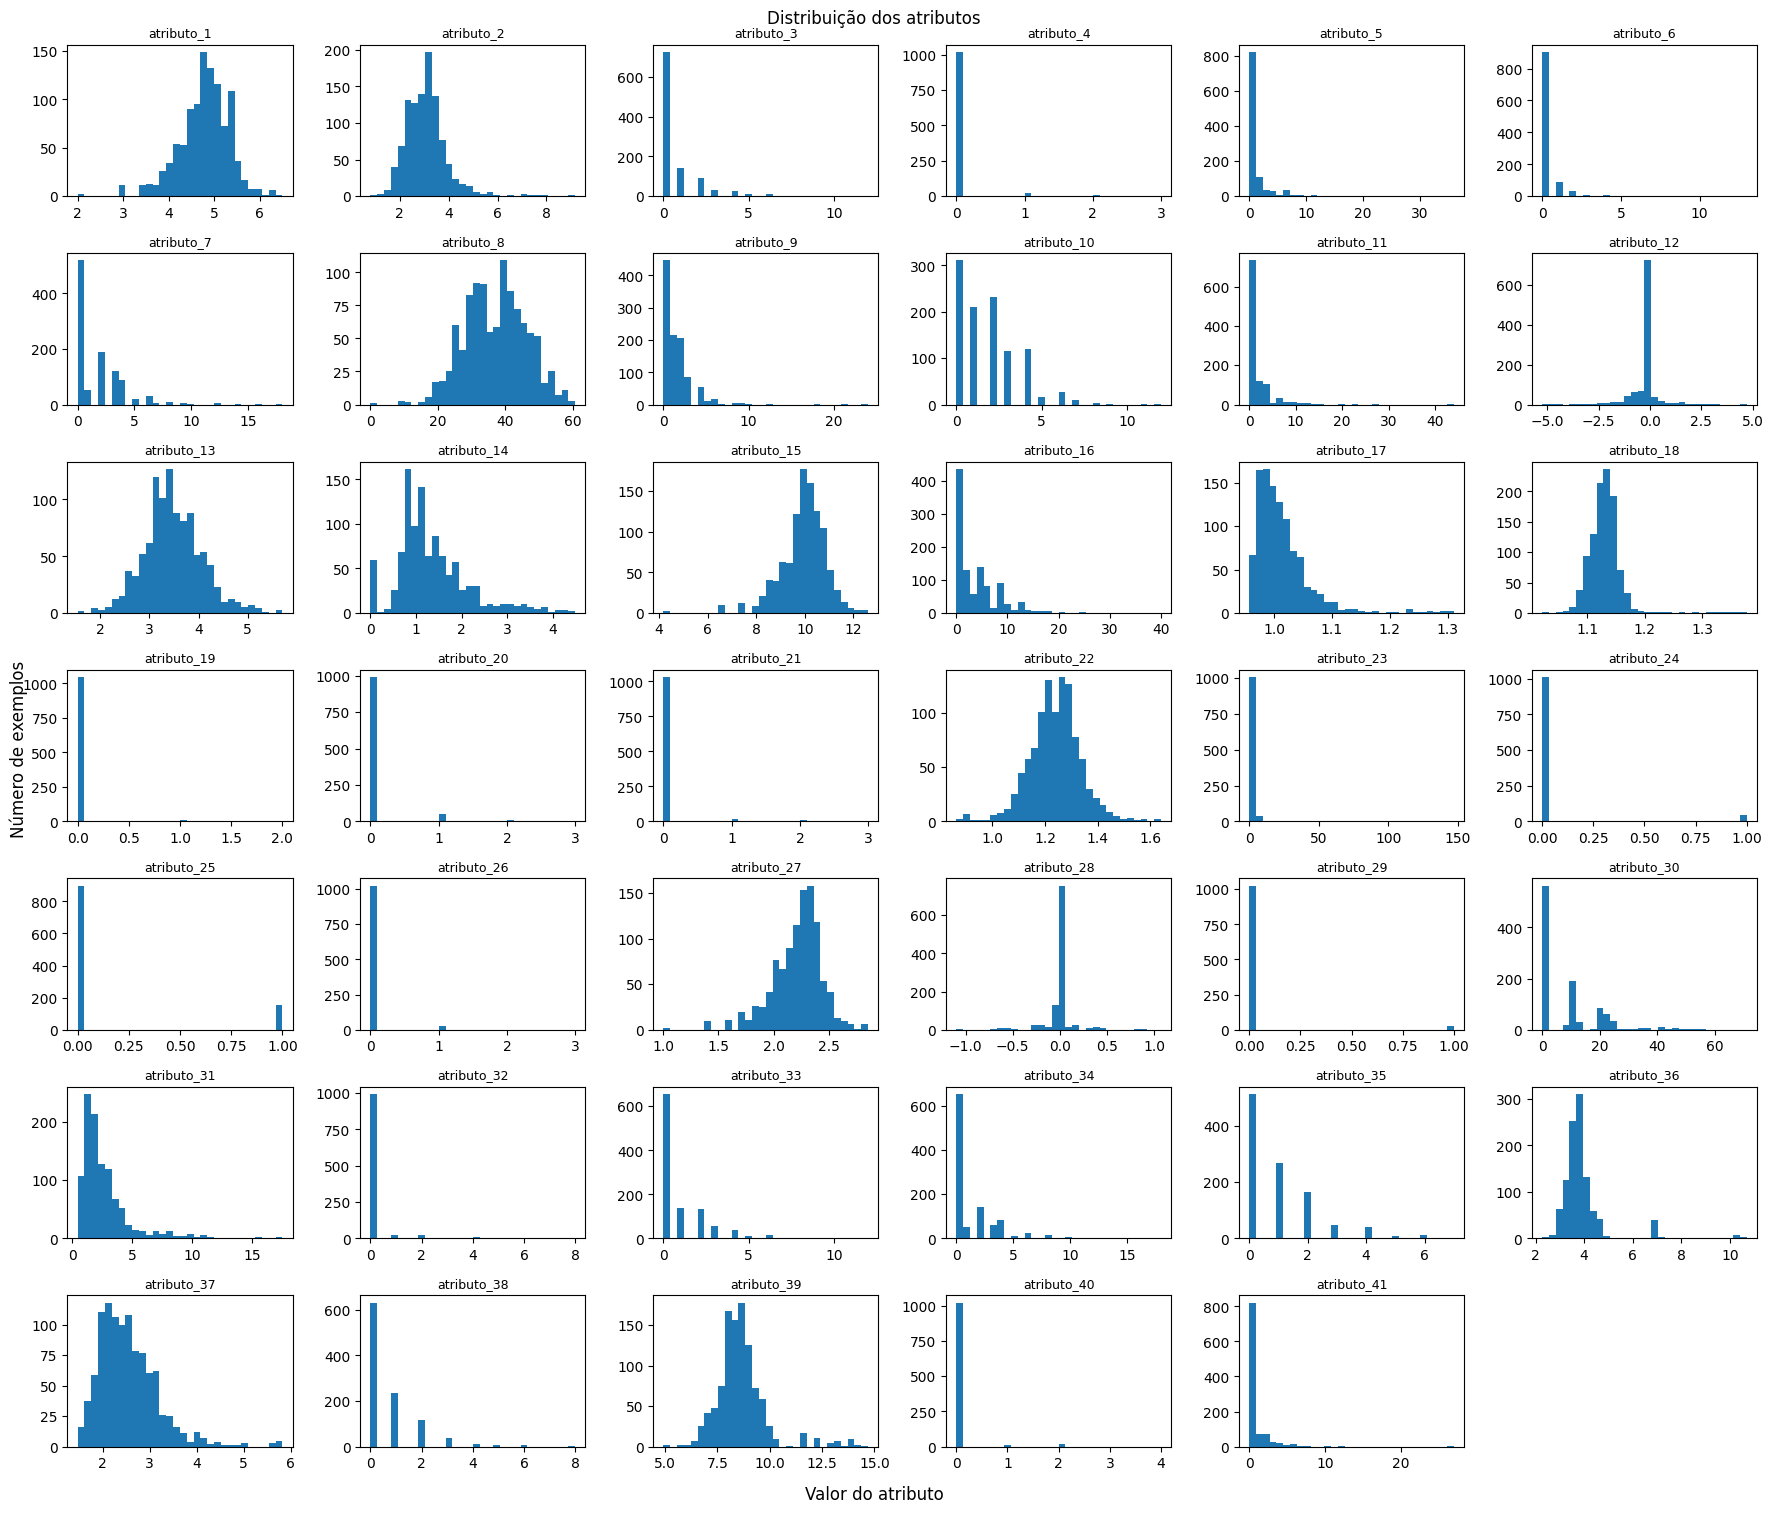

In [16]:
def plota_histogramas(df, colunas_por_linha=6):

    # Resgatamos o número de colunas do dataset
    num_colunas = df.shape[1]
    # Calcula quantas linhas de gráficos são necessárias para organizar os histogramas
    num_linhas = ceil(num_colunas / colunas_por_linha) # np.ceil() vai arredondar o resultado para o próximo inteiro (maior valor)

    fig, eixos = plt.subplots(
        num_linhas, colunas_por_linha, figsize=(3 * colunas_por_linha, 2.2 * num_linhas) # faz com que o tamanho do gráfico acompanhe a largura e altura para que nada fique espremido
    )
    # .ravel() achata a matriz em uma lista de 42 posições 
    eixos = eixos.ravel()
    for eixo, coluna in zip(eixos, df.columns): # o zip() vai juntar as duas listas em pares 
        eixo.hist(df[coluna], bins=NUM_BINS) # bins=30 : divide a faixa de valores em 30 intervalors de mesma largura, contando quantas moléculas caem no mesmo intervalo, sendo essa contagem a altura da barra. 
        eixo.set_title(coluna, fontsize=9)
    for eixo in eixos[num_colunas:]:
        eixo.axis("off") # esconde o eixo que ficou sobrando 

    fig.suptitle("Distribuição dos atributos")
    fig.supxlabel("Valor do atributo")
    fig.supylabel("Número de exemplos")
    fig.tight_layout()
    plt.show()


plota_histogramas(X)

### Relação dos atributos com o target 

In [20]:
# Correlação do atributo com o target: preserva a direção da associação
correlacao_original = X.corrwith(y_binario)

correlacao_abs = X.corrwith(y_binario).abs()

tabela_correlacoes = (
    correlacao_original
    .rename("Correlação")
    .to_frame()
)
# Correlação de cada atributo com o target, em valor absoluto, do maior para o menor.
tabela_correlacoes["Correlação absoluta"] = (
    tabela_correlacoes["Correlação"].abs()
)

tabela_correlacoes = tabela_correlacoes.sort_values(
    "Correlação absoluta",
    ascending=False
)

display(tabela_correlacoes)

,Correlação,Correlação absoluta
atributo_1,-0.395964,0.395964
atributo_27,-0.389434,0.389434
atributo_22,-0.368895,0.368895
atributo_39,-0.365715,0.365715
atributo_15,-0.342781,0.342781
atributo_13,-0.342679,0.342679
atributo_7,-0.336770,0.336770
atributo_33,-0.318216,0.318216
atributo_3,-0.297908,0.297908
atributo_36,-0.288765,0.288765


vai correlacionar os seis primeiros targets com 

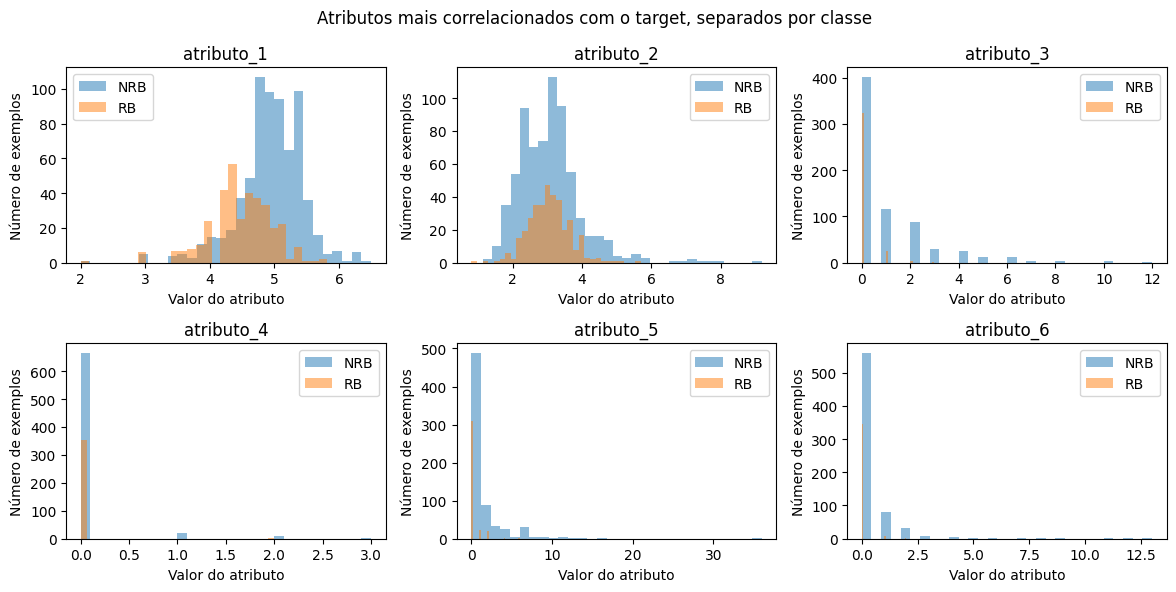

In [23]:
# Nomes dos 6 atributos mais correlacionados
top6 = correlacao_abs.index[:6] # seleciona os elementos desde o início até a posição 6, sem incluí-la

# Um gráfico por atributo, com as duas classes sobrepostas
fig, eixos = plt.subplots(2, 3, figsize=(12, 6))

# Laço que vai percorrer simultaneamente os seis subgráficos e os seis atributos selecionados.
for eixo, atributo in zip(eixos.ravel(), top6): 
    eixo.hist(X.loc[y_str == "NRB", atributo], bins=NUM_BINS, alpha=0.5, label="NRB")
    eixo.hist(X.loc[y_str == "RB", atributo], bins=NUM_BINS, alpha=0.5, label="RB")
    eixo.set_title(atributo)
    eixo.set_xlabel("Valor do atributo")
    eixo.set_ylabel("Número de exemplos")
    eixo.legend()

fig.suptitle("Atributos mais correlacionados com o target, separados por classe")
fig.tight_layout()
plt.show()

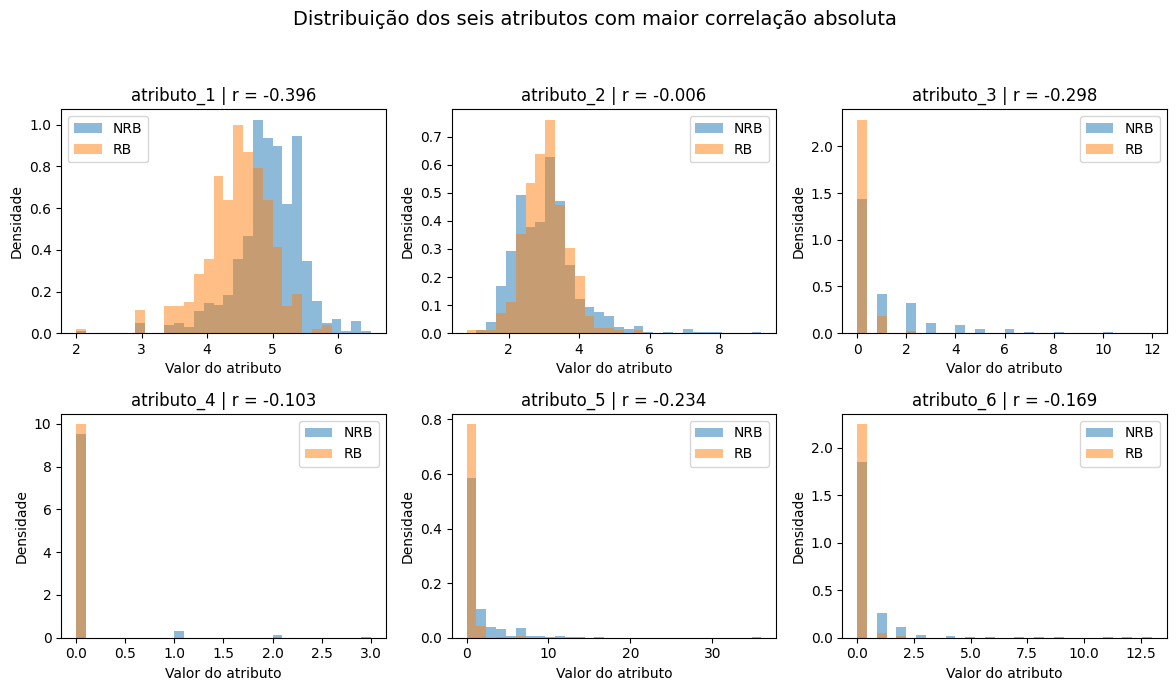

In [26]:
# 4. Cria uma figura com 2 linhas e 3 colunas
fig, eixos = plt.subplots(2, 3, figsize=(12, 7))

# 5. Cria um histograma para cada atributo
for eixo, atributo in zip(eixos.ravel(), top6):

    # Seleciona os valores do atributo para cada classe
    dados_nrb = X.loc[y_str == "NRB", atributo]
    dados_rb = X.loc[y_str == "RB", atributo]

    # Define os mesmos intervalos para as duas classes
    limites_bins = np.histogram_bin_edges(
        X[atributo],
        bins=NUM_BINS
    )

    # Histograma da classe NRB
    eixo.hist(
        dados_nrb,
        bins=limites_bins,
        alpha=0.5,
        density=True,
        label="NRB"
    )

    # Histograma da classe RB
    eixo.hist(
        dados_rb,
        bins=limites_bins,
        alpha=0.5,
        density=True,
        label="RB"
    )

    # Obtém a correlação original do atributo
    r = correlacao_original[atributo]

    # Configurações de cada gráfico
    eixo.set_title(f"{atributo} | r = {r:.3f}")
    eixo.set_xlabel("Valor do atributo")
    eixo.set_ylabel("Densidade")
    eixo.legend()

# Título geral
fig.suptitle(
    "Distribuição dos seis atributos com maior correlação absoluta",
    fontsize=14
)

# Ajusta o espaço entre os gráficos
fig.tight_layout(rect=[0, 0, 1, 0.94])

# Exibe a figura
plt.show()

### Correlação entre atributos 

 atributos muito correlacionados trazem informação repetida (multicolinearidade). Se houver muitos, isso justifica a seleção de atributos ou o PCA, e também afeta como a importância é dividida na explicabilidade.

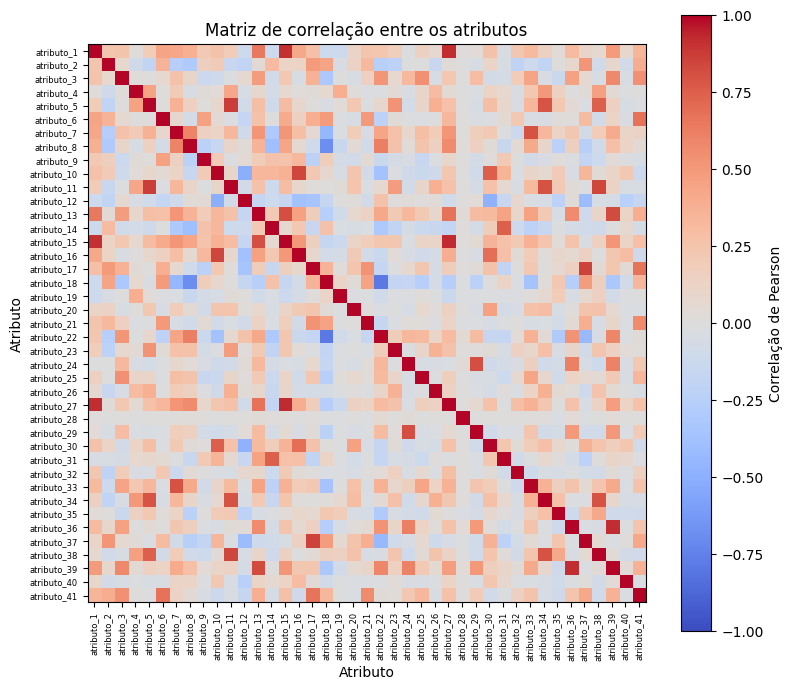

In [27]:
# Função que vai encontrar os pares de atributos que apresentam correlações fortes, considerando o LIMIAR_CORRELAÇÃO definido inicialmente.
def plota_matriz_correlacao(X):
    """Plota a matriz de correlação de Pearson entre os atributos.

    Args:
        X: DataFrame com os atributos.
    """
    # .corr() calcula as correlações entre as colunas numéricas do DataFrame, utilizando a correlação de Pearson por padrão.
    matriz = X.corr()

    fig, eixo = plt.subplots(figsize=(9, 8))
    imagem = eixo.imshow(matriz, cmap="coolwarm", vmin=-1, vmax=1) # transforma os valores da matriz em uma imagem formada por células coloridas 
    eixo.set_xticks(range(X.shape[1]))
    eixo.set_xticklabels(X.columns, rotation=90, fontsize=6)
    eixo.set_yticks(range(X.shape[1]))
    eixo.set_yticklabels(X.columns, fontsize=6)
    eixo.set_title("Matriz de correlação entre os atributos")
    eixo.set_xlabel("Atributo")
    eixo.set_ylabel("Atributo")
    fig.colorbar(imagem, label="Correlação de Pearson")
    plt.show()

plota_matriz_correlacao(X)

### Exemplos redundantes e quase redundantes 

In [29]:
colunas_atributos = list(X.columns)

# Quantas linhas foram removidas na limpeza (duplicatas exatas)
print(f"Linhas removidas no tratamento: {len(df_biodeg) - len(df_biodeg_copy)}")

# Linhas com atributos idênticos a outra linha
num_repetidas = X.duplicated().sum() # .duplicated() marca como True cada linha dos atributos que já apareceu antes, já o .sum() conta a quantidade de duplicatas.
print(f"Linhas com atributos idênticos a outra linha anterior: {num_repetidas}")

# Atributos idênticos, mas classes diferentes?
grupos_exatos = X.groupby(colunas_atributos).ngroup() # o groupby().ngroup() numera os grupos de linhas iguais
classes_por_grupo = y_binario.groupby(grupos_exatos).nunique() # o groupby().nunique() conta quantas classes diferentes há em cada grupo
num_conflitantes = (classes_por_grupo > 1).sum() # um valor diferente de 1 significa que há atributos iguais com classes diferentes
print(f"Grupos de atributos idênticos com classes diferentes: {num_conflitantes}")

# Exemplos quase iguais: arredondar e agrupar, para 0 a 3 casas decimais
resumo = []
for casas in range(0, 4):
    grupos = X.round(casas).groupby(colunas_atributos).ngroup() # .round(casas) vai arrendondar com 1 casa
    tamanhos = grupos.value_counts() # o .vale_counts() conta o tamanho de cada grupo
    resumo.append({
        "casas decimais": casas,
        "número de grupos": len(tamanhos),
        "exemplos em grupos com mais de 1 membro": tamanhos[tamanhos > 1].sum(), # soma só os grupos com mais de uma molécula igual
        "tamanho do maior grupo": tamanhos.max(),
    })

pd.DataFrame(resumo)

Linhas removidas no tratamento: 3
Linhas com atributos idênticos a outra linha anterior: 0
Grupos de atributos idênticos com classes diferentes: 0


,casas decimais,número de grupos,exemplos em grupos com mais de 1 membro,tamanho do maior grupo
0,0,999,91,6
1,1,1039,25,3
2,2,1051,2,2
3,3,1052,0,1


## Divisão de treino e teste 

### Grupo de exemplos redundantes

queremos evitar o vazamento de dados redundantes ou quase redundantes, para isso, vamos formar grupos de exemplos que ficam iguais após o arredondamento e, posteriormente, utilizadmos o GroupShuffleSplit, que vai manter cada grupo inteiro no treino ou no teste. 

In [30]:
# Casas decimais de cada atributo (padrão para todos, com exceções definidas nas pré-definições)
casas_arredondamento = {atributo: CASAS_ARREDONDAMENTO_PADRAO for atributo in X.columns} # esse dicionário diz quantas casas decimais devemos usar em cada atributo. 
casas_arredondamento.update(CASAS_ARREDONDAMENTO_POR_ATRIBUTO) # vai sobrescrever as exceções que listamos.

# Arredondamento de cada coluna com o número de casas
X_arredondado = X.round(casas_arredondamento)
grupos = X_arredondado.groupby(list(X.columns)).ngroup() 

print(f"Número de exemplos: {len(X)}")
print(f"Grupos únicos: {grupos.nunique()}")

Número de exemplos: 1052
Grupos únicos: 1051


### Split treino/teste

In [31]:
# O GroupShuffleSplit sorteia grupos inteiros para o teste até chegar em 20% dos exemplos - a quantidade do grupo teste que queremos coletar
divisor = GroupShuffleSplit(n_splits=1, test_size=TAMANHO_TESTE, random_state=SEMENTE_ALEATORIA)
indices_treino, indices_teste = next(divisor.split(X, y_binario, groups=grupos)) # next(): pega a primeira divisão, como posições das linhas

# iloc: seleciona as linhas por posição
X_treino, X_teste = X.iloc[indices_treino], X.iloc[indices_teste]
y_treino, y_teste = y_binario.iloc[indices_treino], y_binario.iloc[indices_teste]
# Vai guardar os grupos do treino para utilizar na validação cruzada
grupos_treino = grupos.iloc[indices_treino]

print(f"Exemplos de treino: {len(X_treino)} | Exemplos de teste: {len(X_teste)}")
print("\nProporção da classe RB (classe 1) em cada conjunto:")
print(f"  Todos os dados: {y_binario.mean():.3f}") # é a proporção de RB
print(f"  Treino:         {y_treino.mean():.3f}")
print(f"  Teste:          {y_teste.mean():.3f}")

Exemplos de treino: 841 | Exemplos de teste: 211

Proporção da classe RB (classe 1) em cada conjunto:
  Todos os dados: 0.337
  Treino:         0.329
  Teste:          0.365


### Checando a qualidade do split 

Se o split for saudável, os exemplos de teste não estão sistematicamente mais perto do treino do que o treino está de si mesmo. O professor mede isso com a menor distância Manhattan entre exemplos e um teste de hipótese. 

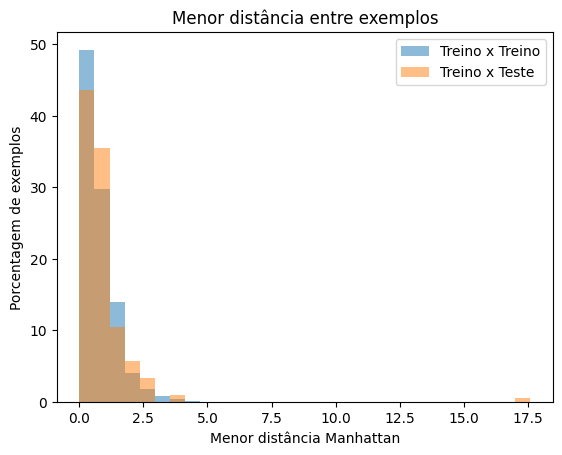

p-valor = 0.09455574790309318
Não rejeitar H0: pode haver vazamento!


In [32]:
# Normalização ajustada apenas no treino, para as distâncias ficarem comparáveis
normalizador = MinMaxScaler() # coloca os atributos do treino entre 0 e 1 para que não haja dominância daqueles com escala maior
normalizador.fit(X_treino) 
X_treino_norm = normalizador.transform(X_treino)
X_teste_norm = normalizador.transform(X_teste)

# Menor distância de cada exemplo de treino a OUTRO exemplo de treino
vizinhos = NearestNeighbors(n_neighbors=1, metric="manhattan", n_jobs=-1)
vizinhos.fit(X_treino_norm)
treino_treino, _ = vizinhos.kneighbors()   # sem argumentos: ignora o próprio exemplo
treino_treino = treino_treino.ravel()

# Menor distância de cada exemplo de teste ao treino
treino_teste = cdist(X_treino_norm, X_teste_norm, "cityblock").min(axis=0)

bins = np.histogram_bin_edges(np.concatenate([treino_treino, treino_teste]), bins=NUM_BINS)
plt.hist(
    treino_treino, bins=bins, alpha=0.5, label="Treino x Treino",
    weights=np.full(len(treino_treino), 100 / len(treino_treino)),
)
plt.hist(
    treino_teste, bins=bins, alpha=0.5, label="Treino x Teste",
    weights=np.full(len(treino_teste), 100 / len(treino_teste)),
)
plt.title("Menor distância entre exemplos")
plt.xlabel("Menor distância Manhattan")
plt.ylabel("Porcentagem de exemplos")
plt.legend()
plt.show()

# Teste de Mann-Whitney: compara duas amostras sem supor distribuição normal
resultado = mannwhitneyu(treino_treino, treino_teste, alternative="less")
pvalor = resultado.pvalue
print("p-valor =", pvalor)

if pvalor < 1 - NIVEL_CONFIANCA:
    print("Rejeitar H0: split saudável.")
else:
    print("Não rejeitar H0: pode haver vazamento!")

## Modelo Baseline e validação cruzada

O baseline é um modelo “bobo” usado como referência: todo modelo treinado precisa superá-lo. Aqui, ele sempre prevê a classe mais frequente

Validação cruzada: O treino é dividido em 5 partes (folds). Em cada uma de 5 rodadas, treina-se com 4 partes e mede-se na restante; o resultado são 5 notas, de que se tira a média e o desvio padrão. Isso dá uma estimativa do desempenho sem tocar no teste. O 

In [33]:
validacao_cruzada = StratifiedGroupKFold(
    n_splits=NUM_FOLDS, shuffle=True, random_state=SEMENTE_ALEATORIA
)

baseline = DummyClassifier(strategy="most_frequent")

# cross_val_score: faz as rodadas e devolve as notas 
pontuacoes_baseline = cross_val_score(
    baseline, X_treino, y_treino,
    cv=validacao_cruzada, groups=grupos_treino, scoring=METRICA, n_jobs=-1,
)
acuracias_baseline = cross_val_score(
    baseline, X_treino, y_treino,
    cv=validacao_cruzada, groups=grupos_treino, scoring="accuracy", n_jobs=-1,
)

print(f"Baseline, {METRICA}: {pontuacoes_baseline.mean():.3f} ± {pontuacoes_baseline.std():.3f}")
print(f"Baseline, acurácia: {acuracias_baseline.mean():.3f} ± {acuracias_baseline.std():.3f}")

Baseline, balanced_accuracy: 0.500 ± 0.000
Baseline, acurácia: 0.671 ± 0.032


## Pipelines e otimização com Optuna 

### Redução de dimensionalidade ou seleção de atributos

In [34]:
NUM_ATRIBUTOS = X_treino.shape[1]


def cria_reducao(trial, num_atributos):
    """Cria a etapa de redução de dimensionalidade ou seleção de atributos, controlada pelo Optuna.

    Args:
        trial: Objeto trial do Optuna.
        num_atributos: Número de atributos do dataset.

    Returns:
        Um transformador do scikit-learn ou "passthrough" (não faz nada).
    """
    # trial: representa uma tentativa; suggest_: pedem ao optuna um valor para um hiperparâmetro
    tipo = trial.suggest_categorical("reducao", ["nenhuma", "pca", "selecao"])#  suggest_categorical(): pede uma oção de uma lista.

    if tipo == "pca":
        num_componentes = trial.suggest_int("pca_num_componentes", 5, num_atributos) # suggest_int(): pede um inteiro num intervalo 
        # PCA: cria novas variáveis, combinações dos atributos originais, que concentram a maior parte da vairação dos dados. 
        return PCA(n_components=num_componentes, random_state=SEMENTE_ALEATORIA)

    if tipo == "selecao":
        num_selecionados = trial.suggest_int("selecao_num_atributos", 5, num_atributos) # suggest_float(): pede um decimal sorteado em escala logaritmica.
        return SelectKBest(score_func=f_classif, k=num_selecionados) # SelectKbest: mantém os k atributos com maior relação estatística com o target. 

    return "passthrough" # manda o pipeline pular a etapa. 

### Regressão logística 

In [35]:
def cria_pipeline_regressao_logistica(trial):
    """Cria o pipeline de regressão logística com hiperparâmetros sugeridos pelo Optuna."""
    modelo = LogisticRegression(
        C=trial.suggest_float("C", 1e-3, 1e2, log=True),
        penalty=trial.suggest_categorical("penalty", ["l1", "l2"]),
        class_weight=trial.suggest_categorical("class_weight", [None, "balanced"]),
        solver="liblinear",
        max_iter=5000,
    )
    return Pipeline([
        ("normalizador", StandardScaler()),
        ("reducao", cria_reducao(trial, NUM_ATRIBUTOS)),
        ("modelo", modelo),
    ])

### K-Nearest Neighbors (KNN)

In [36]:
def cria_pipeline_knn(trial):
    """Cria o pipeline do KNN com hiperparâmetros sugeridos pelo Optuna."""
    modelo = KNeighborsClassifier(
        n_neighbors=trial.suggest_int("n_neighbors", 1, 50),
        weights=trial.suggest_categorical("weights", ["uniform", "distance"]),
        p=trial.suggest_categorical("p", [1, 2]),
    )
    return Pipeline([
        ("normalizador", StandardScaler()),
        ("reducao", cria_reducao(trial, NUM_ATRIBUTOS)),
        ("modelo", modelo),
    ])

### Floresta aleatória 

In [37]:
def cria_pipeline_floresta_aleatoria(trial):
    """Cria o pipeline da floresta aleatória com hiperparâmetros sugeridos pelo Optuna."""
    modelo = RandomForestClassifier(
        n_estimators=trial.suggest_int("n_estimators", 100, 500, step=50),
        max_depth=trial.suggest_int("max_depth", 3, 30),
        min_samples_leaf=trial.suggest_int("min_samples_leaf", 1, 10),
        max_features=trial.suggest_float("max_features", 0.1, 1.0),
        class_weight=trial.suggest_categorical("class_weight", [None, "balanced"]),
        random_state=SEMENTE_ALEATORIA,
    )
    return Pipeline([("modelo", modelo)])


### (SVM)

In [38]:
def cria_pipeline_svm(trial):
    """Cria o pipeline da SVM (kernel RBF) com hiperparâmetros sugeridos pelo Optuna."""
    modelo = SVC(
        kernel="rbf",
        C=trial.suggest_float("C", 1e-2, 1e3, log=True),
        gamma=trial.suggest_float("gamma", 1e-4, 1e0, log=True),
        class_weight=trial.suggest_categorical("class_weight", [None, "balanced"]),
    )
    return Pipeline([
        ("normalizador", StandardScaler()),
        ("reducao", cria_reducao(trial, NUM_ATRIBUTOS)),
        ("modelo", modelo),
    ])

### Gradiente Boosting

In [39]:
def cria_pipeline_gradient_boosting(trial):
    """Cria o pipeline do gradient boosting com hiperparâmetros sugeridos pelo Optuna."""
    modelo = HistGradientBoostingClassifier(
        learning_rate=trial.suggest_float("learning_rate", 0.01, 0.3, log=True),
        max_iter=trial.suggest_int("max_iter", 50, 400),
        max_leaf_nodes=trial.suggest_int("max_leaf_nodes", 4, 31),
        min_samples_leaf=trial.suggest_int("min_samples_leaf", 5, 50),
        l2_regularization=trial.suggest_float("l2_regularization", 1e-3, 10.0, log=True),
        class_weight=trial.suggest_categorical("class_weight", [None, "balanced"]),
        random_state=SEMENTE_ALEATORIA,
    )
    return Pipeline([("modelo", modelo)])

### Otimização do Optuna 

In [41]:
def funcao_objetivo(trial, cria_pipeline):
    """Calcula a métrica média em validação cruzada para os hiperparâmetros sugeridos.

    Args:
        trial: Objeto trial do Optuna.
        cria_pipeline: Função que recebe o trial e devolve um pipeline do scikit-learn.

    Returns:
        Média da métrica nos folds da validação cruzada (o Optuna a maximiza).
    """
    pipeline = cria_pipeline(trial)
    pontuacoes = cross_val_score(
        pipeline, X_treino, y_treino,
        cv=validacao_cruzada, groups=grupos_treino, scoring=METRICA, n_jobs=-1,
    )
    return pontuacoes.mean()

In [43]:
# Criamos um dicionário com todas as funções para percorrê-las com um laço
ALGORITMOS = {
    "Regressão logística": cria_pipeline_regressao_logistica,
    "KNN": cria_pipeline_knn,
    "SVM": cria_pipeline_svm,
    "Floresta aleatória": cria_pipeline_floresta_aleatoria,
    "Gradient boosting": cria_pipeline_gradient_boosting,
}

In [44]:
estudos = {}

for nome, cria_pipeline in ALGORITMOS.items():
    estudo = optuna.create_study(
        study_name=f"estudo_{nome}",
        storage=f"sqlite:///{ARQUIVO_ESTUDOS}",
        load_if_exists=True,
        direction="maximize",
        sampler=optuna.samplers.TPESampler(seed=SEMENTE_ALEATORIA),
    )

    tentativas_restantes = NUM_TENTATIVAS - len(estudo.trials)
    if tentativas_restantes > 0:
        estudo.optimize(partial(funcao_objetivo, cria_pipeline=cria_pipeline), n_trials=tentativas_restantes)

    estudos[nome] = estudo
    print(f"{nome}: melhor {METRICA} na validação cruzada = {estudo.best_value:.4f}")

Regressão logística: melhor balanced_accuracy na validação cruzada = 0.8659
KNN: melhor balanced_accuracy na validação cruzada = 0.8508
SVM: melhor balanced_accuracy na validação cruzada = 0.8631
Floresta aleatória: melhor balanced_accuracy na validação cruzada = 0.8624
Gradient boosting: melhor balanced_accuracy na validação cruzada = 0.8653


### Convergência e melhores hiperparâmetros

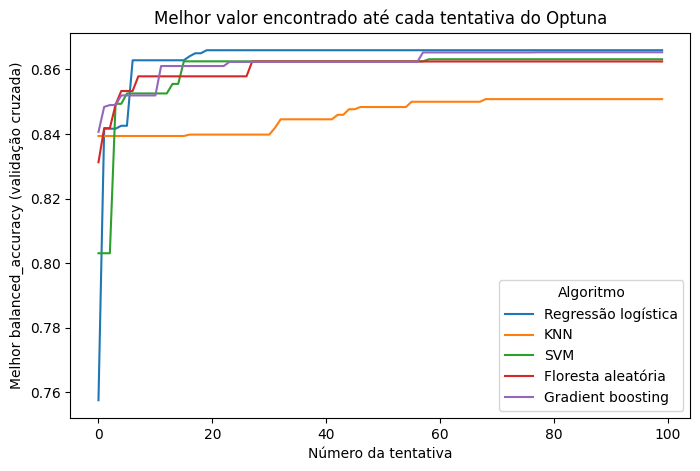

Regressão logística: {'C': 0.6391442644506002, 'penalty': 'l1', 'class_weight': 'balanced', 'reducao': 'nenhuma'}
KNN: {'n_neighbors': 25, 'weights': 'distance', 'p': 2, 'reducao': 'pca', 'pca_num_componentes': 32}
SVM: {'C': 222.69713659322431, 'gamma': 0.00010063414347883579, 'class_weight': 'balanced', 'reducao': 'selecao', 'selecao_num_atributos': 41}
Floresta aleatória: {'n_estimators': 350, 'max_depth': 7, 'min_samples_leaf': 4, 'max_features': 0.158726427763975, 'class_weight': 'balanced'}
Gradient boosting: {'learning_rate': 0.011718522933840844, 'max_iter': 296, 'max_leaf_nodes': 26, 'min_samples_leaf': 9, 'l2_regularization': 0.013275269041506705, 'class_weight': 'balanced'}


In [45]:
fig, eixo = plt.subplots(figsize=(8, 5))
for nome, estudo in estudos.items():
    valores = estudo.trials_dataframe()["value"]
    eixo.plot(valores.cummax().values, label=nome)

eixo.set_title("Melhor valor encontrado até cada tentativa do Optuna")
eixo.set_xlabel("Número da tentativa")
eixo.set_ylabel(f"Melhor {METRICA} (validação cruzada)")
eixo.legend(title="Algoritmo")
plt.show()

for nome, estudo in estudos.items():
    print(f"{nome}: {estudo.best_params}")

## Comparação dos modelos 

In [46]:
validacao_cruzada_comparacao = StratifiedGroupKFold(
    n_splits=NUM_FOLDS, shuffle=True, random_state=SEMENTE_ALEATORIA + 1
)

pontuacoes_cv = {
    "Baseline": cross_val_score(
        baseline, X_treino, y_treino,
        cv=validacao_cruzada_comparacao, groups=grupos_treino, scoring=METRICA, n_jobs=-1,
    )
}
melhores_pipelines = {}

for nome, estudo in estudos.items():
    # Recria o pipeline com os melhores hiperparâmetros encontrados
    pipeline = ALGORITMOS[nome](optuna.trial.FixedTrial(estudo.best_params))
    melhores_pipelines[nome] = pipeline
    pontuacoes_cv[nome] = cross_val_score(
        pipeline, X_treino, y_treino,
        cv=validacao_cruzada_comparacao, groups=grupos_treino, scoring=METRICA, n_jobs=-1,
    )

tabela_comparacao = pd.DataFrame({
    "média": {nome: pont.mean() for nome, pont in pontuacoes_cv.items()},
    "desvio padrão": {nome: pont.std() for nome, pont in pontuacoes_cv.items()},
}).sort_values("média", ascending=False)

tabela_comparacao

,média,desvio padrão
Gradient boosting,0.860840,0.023376
SVM,0.854353,0.035344
Floresta aleatória,0.852658,0.019459
Regressão logística,0.850151,0.023346
KNN,0.839830,0.025121
Baseline,0.500000,0.000000


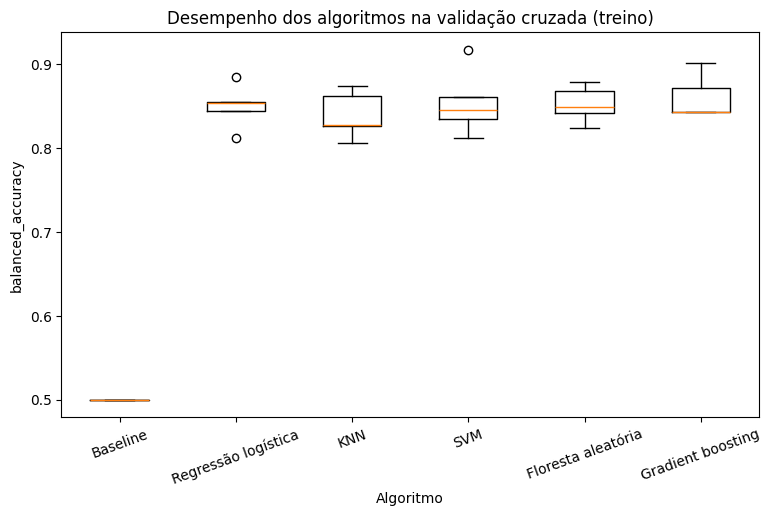

In [47]:
nomes = list(pontuacoes_cv.keys())

fig, eixo = plt.subplots(figsize=(9, 5))
eixo.boxplot([pontuacoes_cv[nome] for nome in nomes])
eixo.set_xticks(range(1, len(nomes) + 1))
eixo.set_xticklabels(nomes, rotation=20)
eixo.set_title("Desempenho dos algoritmos na validação cruzada (treino)")
eixo.set_xlabel("Algoritmo")
eixo.set_ylabel(METRICA)
plt.show()

## Avaliação final no teste

In [48]:
def pontuacao_continua(modelo, X):
    """Devolve a pontuação contínua da classe positiva (usada na curva ROC e no AUC).

    Args:
        modelo: Modelo treinado.
        X: Atributos.

    Returns:
        Array com a probabilidade, ou a função de decisão quando o modelo não tem probabilidades.
    """
    if hasattr(modelo, "predict_proba"):
        return modelo.predict_proba(X)[:, 1]
    return modelo.decision_function(X)


def calcula_metricas(modelo, X, y):
    """Calcula as métricas de classificação binária (classe positiva: RB).

    Args:
        modelo: Modelo treinado.
        X: Atributos.
        y: Target real (0 ou 1).

    Returns:
        Dicionário com as métricas.
    """
    previsoes = modelo.predict(X)
    return {
        "acurácia": accuracy_score(y, previsoes),
        "acurácia balanceada": balanced_accuracy_score(y, previsoes),
        "precisão": precision_score(y, previsoes, zero_division=0),
        "recall": recall_score(y, previsoes, zero_division=0),
        "F1": f1_score(y, previsoes, zero_division=0),
        "AUC ROC": roc_auc_score(y, pontuacao_continua(modelo, X)),
    }


candidatos = tabela_comparacao.drop(index="Baseline")
nome_melhor_modelo = candidatos["média"].idxmax()
print(f"Melhor algoritmo na validação cruzada: {nome_melhor_modelo}")

modelo_final = melhores_pipelines[nome_melhor_modelo]
modelo_final.fit(X_treino, y_treino)
baseline.fit(X_treino, y_treino)

metricas_teste = pd.DataFrame({
    "Baseline": calcula_metricas(baseline, X_teste, y_teste),
    nome_melhor_modelo: calcula_metricas(modelo_final, X_teste, y_teste),
}).T

metricas_teste

Melhor algoritmo na validação cruzada: Gradient boosting


,acurácia,acurácia balanceada,precisão,recall,F1,AUC ROC
Baseline,0.635071,0.500000,0.000000,0.000000,0.0,0.50000
Gradient boosting,0.857820,0.841103,0.821918,0.779221,0.8,0.90221


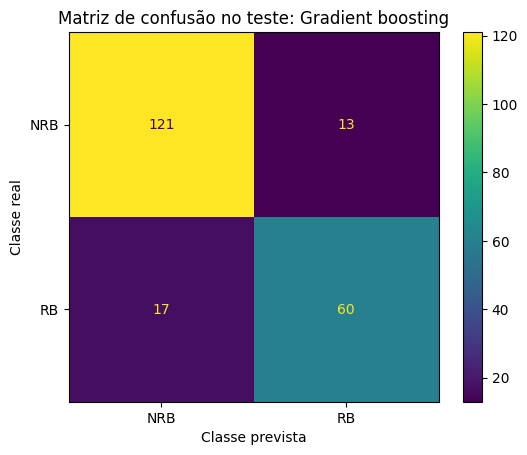

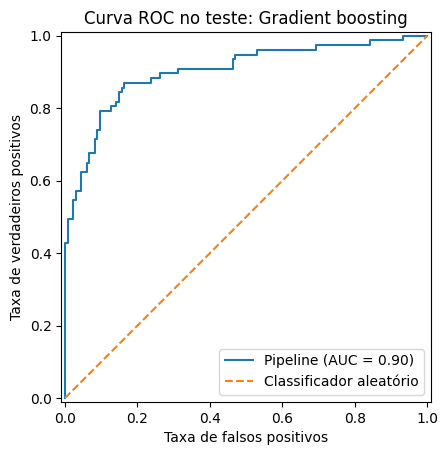

In [49]:
ConfusionMatrixDisplay.from_estimator(
    modelo_final, X_teste, y_teste, display_labels=["NRB", "RB"]
)
plt.title(f"Matriz de confusão no teste: {nome_melhor_modelo}")
plt.xlabel("Classe prevista")
plt.ylabel("Classe real")
plt.show()

RocCurveDisplay.from_estimator(modelo_final, X_teste, y_teste)
plt.plot([0, 1], [0, 1], linestyle="--", label="Classificador aleatório")
plt.title(f"Curva ROC no teste: {nome_melhor_modelo}")
plt.xlabel("Taxa de falsos positivos")
plt.ylabel("Taxa de verdadeiros positivos")
plt.legend()
plt.show()

## Explicabilidade

In [52]:
resultado_permutacao = permutation_importance(
    modelo_final, X_teste, y_teste,
    scoring=METRICA, n_repeats=30, random_state=SEMENTE_ALEATORIA, n_jobs=-1,
)

importancias = pd.DataFrame({
    "atributo": X_teste.columns,
    "média": resultado_permutacao.importances_mean,
    "desvio padrão": resultado_permutacao.importances_std,
}).sort_values("média", ascending=False)

top15 = importancias.head(15).iloc[::-1]   # invertido para o maior ficar no topo do gráfico

fig, eixo = plt.subplots(figsize=(8, 6))
eixo.barh(top15["atributo"], top15["média"], xerr=top15["desvio padrão"])
eixo.set_title("Importância por permutação (15 atributos mais importantes)")
eixo.set_xlabel(f"Queda média em {METRICA}")
eixo.set_ylabel("Atributo")
plt.show()
 
#oii

c:\venv\ilumpy\Lib\site-packages\sklearn\inspection\_partial_dependence.py:717: FutureWarning: The column 37 contains integer data. Partial dependence plots are not supported for integer data: this can lead to implicit rounding with NumPy arrays or even errors with newer pandas versions. Please convert numerical featuresto floating point dtypes ahead of time to avoid problems. This will raise ValueError in scikit-learn 1.9.
  warnings.warn(


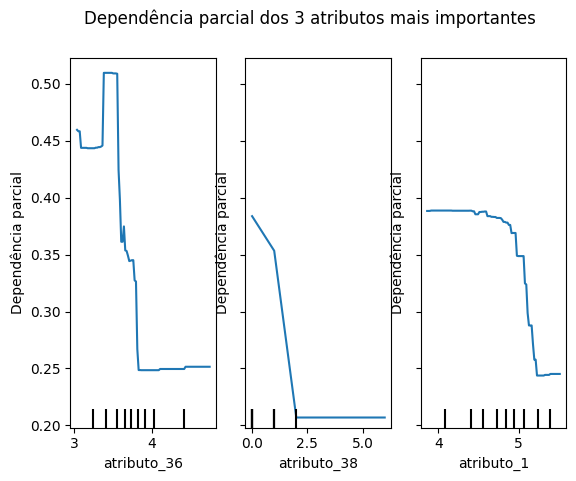

In [51]:
top3 = importancias["atributo"].head(3).tolist()

grafico_dependencia = PartialDependenceDisplay.from_estimator(modelo_final, X_treino, features=top3)
grafico_dependencia.figure_.suptitle("Dependência parcial dos 3 atributos mais importantes")
for eixo in grafico_dependencia.axes_.ravel():
    if eixo is not None:
        eixo.set_ylabel("Dependência parcial")
plt.show()

# Conclusões e principais aprendizados 

# Referências bibliográficas 

# Descrição do uso de IA neste trabalho